# astrovodka Demo — TNG-100 Subhalo 7 at z=0.02

This notebook demonstrates two key features of **astrovodka**:

1. **3D data products**: compute and visualize UV field, DM/HI/H₂ density grids
   in comoving real-space and redshift-space
2. **Mock radio cubes**: generate synthetic HI data cubes with Gaussian noise
   at two different angular resolutions (10 arcsec and 3 arcmin FWHM)

**Setup:** TNG-100 snapshot 99, subhalo 7 (120 gas particles), placed at observed redshift z=0.02.


## 1. Environment Setup

In [1]:
import sys
sys.path.insert(0, '/home/zerui603/work/astrovodka/astrovodka.0.1')

import os, numpy as np
import astropy.units as U
from astropy.cosmology import Planck15
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm, Normalize
import h5py
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 150, 'figure.figsize': (16, 5)})

from astrovodka import Martini, DataCube, SubhaloDataProducts
from astrovodka.sources import TNGSource
from astrovodka.beams import GaussianBeam
from astrovodka.noise import GaussianNoise
from astrovodka.spectral_models import GaussianSpectrum
from astrovodka.sph_kernels import CubicSplineKernel
from astrovodka.cosmology_utils import luminosity_distance, angular_diameter_distance

print('All imports successful')


All imports successful


## 2. Configuration

- **TNG data:** TNG-100 snapshot 99, subhalo 7 (120 gas particles)
- **Observed redshift:** z = 0.02 (D<sub>L</sub> ≈ 90 Mpc, D<sub>A</sub> ≈ 86 Mpc with Planck15)
- **Output directory:** `./examplefiles/`


In [2]:
# ===== Configuration =====
basePath = '/data/hw2/projects/FAST/HD2_high/TNG/TNG-100/'
snapNum = 99          # z ≈ 0 snapshot
subID   = 7            # small subhalo, 120 gas particles
Z_OBS   = 0.02         # observed redshift

OUTDIR  = '/home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/'
os.makedirs(OUTDIR, exist_ok=True)

cosmo = Planck15
DL = luminosity_distance(Z_OBS, cosmo)
DA = angular_diameter_distance(Z_OBS, cosmo)
scale = (DA.to(U.kpc) / U.rad).to(U.kpc / U.arcsec)

print(f'Observed redshift: z = {Z_OBS}')
print(f'Luminosity distance:  D_L = {DL:.1f}')
print(f'Angular diam. dist.:  D_A = {DA:.1f}')
print(f'Physical scale: 1 arcsec = {scale.value:.2f} kpc')
print(f'Output directory: {OUTDIR}')


Observed redshift: z = 0.02
Luminosity distance:  D_L = 89.9 Mpc
Angular diam. dist.:  D_A = 86.4 Mpc
Physical scale: 1 arcsec = 0.42 kpc
Output directory: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/


## 3. Load the Subhalo with K13 Model

Use `TNGSource` with `observed_redshift=0.02` to:
- Load gas particles from the TNG snapshot
- Compute per-particle HI/H₂ masses via the K13 volumetric model (global UVB mode)
- Place the source at the cosmological distance corresponding to z=0.02


In [3]:
print('Loading subhalo with K13 HI model...')
source = TNGSource(
    basePath=basePath,
    snapNum=snapNum,
    subID=subID,
    uv_mode='global',
    observed_redshift=Z_OBS,
    load_subhalo_only=True,
    ra=30.0 * U.deg,
    dec=45.0 * U.deg,
)

print(f'\nSource summary:')
print(f'  Particles:          {source.npart}')
print(f'  Snapshot redshift:  {source.source_redshift:.6f}')
print(f'  D_L:                {source.D_L:.1f}')
print(f'  D_A:                {source.D_A:.1f}')
print(f'  Systemic velocity:  {source.vsys.to(U.km/U.s):.0f}')
print(f'  Total HI mass:      {source.input_mass:.2e}')
print(f'  Total H2 mass:      {source.m_H2_g.sum():.2e}')
print(f'  H2/HI ratio:        {source.m_H2_g.sum() / source.input_mass:.4f}')

# Compute adaptive spatial/spectral extents from particle coordinates
xyz = source.coordinates_g.get_xyz()
vxyz = source.coordinates_g.differentials['s'].get_d_xyz()

# Sky plane extents (y, z axes in physical kpc)
y_min, y_max = xyz[1].min().to_value(U.kpc), xyz[1].max().to_value(U.kpc)
z_min, z_max = xyz[2].min().to_value(U.kpc), xyz[2].max().to_value(U.kpc)
y_extent_kpc = 1.1 * (y_max - y_min)
z_extent_kpc = 1.1 * (z_max - z_min)

# Angular extents (arcsec) on the sky
y_extent_arcsec = y_extent_kpc / scale.value
z_extent_arcsec = z_extent_kpc / scale.value

# LOS velocity extent
vx_min = vxyz[0].min().to_value(U.km / U.s)
vx_max = vxyz[0].max().to_value(U.km / U.s)
v_extent_kms = 1.1 * max(abs(vx_max - vx_min), 20.0)  # at least 20 km/s

print(f'\nAdaptive extents (1.1× particle range):')
print(f'  Sky Y (RA):  {y_extent_arcsec:.1f} arcsec ({y_extent_kpc:.1f} kpc)')
print(f'  Sky Z (Dec): {z_extent_arcsec:.1f} arcsec ({z_extent_kpc:.1f} kpc)')
print(f'  LOS velocity: {v_extent_kms:.0f} km/s')

Loading subhalo with K13 HI model...
Loading TNG snapshot 99, subhalo 7...
  Redshift: 0.0000, h: 0.6774, scale factor: 1.0000
  Observed redshift (for distance): 0.0200
  Luminosity distance: 89.9 Mpc
  Angular diameter distance: 86.4 Mpc
  Loading gas particles (subhalo)...
  Loaded 120 gas particles
  Computing K13 HI/H2 masses (uv_mode=global)...
    Global UVB: U_MW = 0.0014
    Total HI mass: 1.5982e-09 x 1e10 Msun
    Total H2 mass: 0.0000e+00 x 1e10 Msun
  TNGSource initialized: 120 particles
  vsys = 6024.1 km / s

Source summary:
  Particles:          120
  Snapshot redshift:  0.000000
  D_L:                89.9 Mpc
  D_A:                86.4 Mpc
  Systemic velocity:  6024 km / s
  Total HI mass:      1.60e+01 solMass
  Total H2 mass:      0.00e+00 solMass
  H2/HI ratio:        0.0000

Adaptive extents (1.1× particle range):
  Sky Y (RA):  94.9 arcsec (39.8 kpc)
  Sky Z (Dec): 130.0 arcsec (54.4 kpc)
  LOS velocity: 364 km/s


---
## 4. Task 1 — 3D Data Products

Compute gridded 3D data products using `SubhaloDataProducts.from_subhalo()`.

### Products computed (all on a 64³ comoving grid):
| Grid | Description |
|------|-------------|
| `uv_field` | UV radiation field [Draine units] |
| `dm_real` | Dark matter density — comoving real space |
| `dm_rsd` | Dark matter density — redshift space |
| `hi_real` | HI mass density — comoving real space |
| `hi_rsd` | HI mass density — redshift space |
| `h2_real` | H₂ mass density — comoving real space |
| `h2_rsd` | H₂ mass density — redshift space |


In [4]:
print('Computing 3D data products (ngrid=64)...')
dp = SubhaloDataProducts.from_subhalo(
    basePath=basePath,
    snapNum=snapNum,
    subID=subID,
    ngrid=64,
    uv_mode='global',
    load_subhalo_only=True,
    cosmology=cosmo,
)

# Save to HDF5
h5_path = os.path.join(OUTDIR, f'sub{subID}_z{Z_OBS}_data_products.hdf5')
dp.save_hdf5(h5_path)
print(f'Saved: {h5_path}')
print(f'Grid shape: {dp.dm_real.shape}')
print(f'Grid bounds [ckpc/h]: x=[{dp.metadata["grid_bounds_ckpc_h"][0]:.0f}, {dp.metadata["grid_bounds_ckpc_h"][1]:.0f}]')


Computing 3D data products (ngrid=64)...
Saved: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/sub7_z0.02_data_products.hdf5
Grid shape: (64, 64, 64)
Grid bounds [ckpc/h]: x=[1099, 1577]


### 4.1 Visualize — DM & HI Density Projections

Saved: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/sub7_z0.02_DM_HI_projections.png


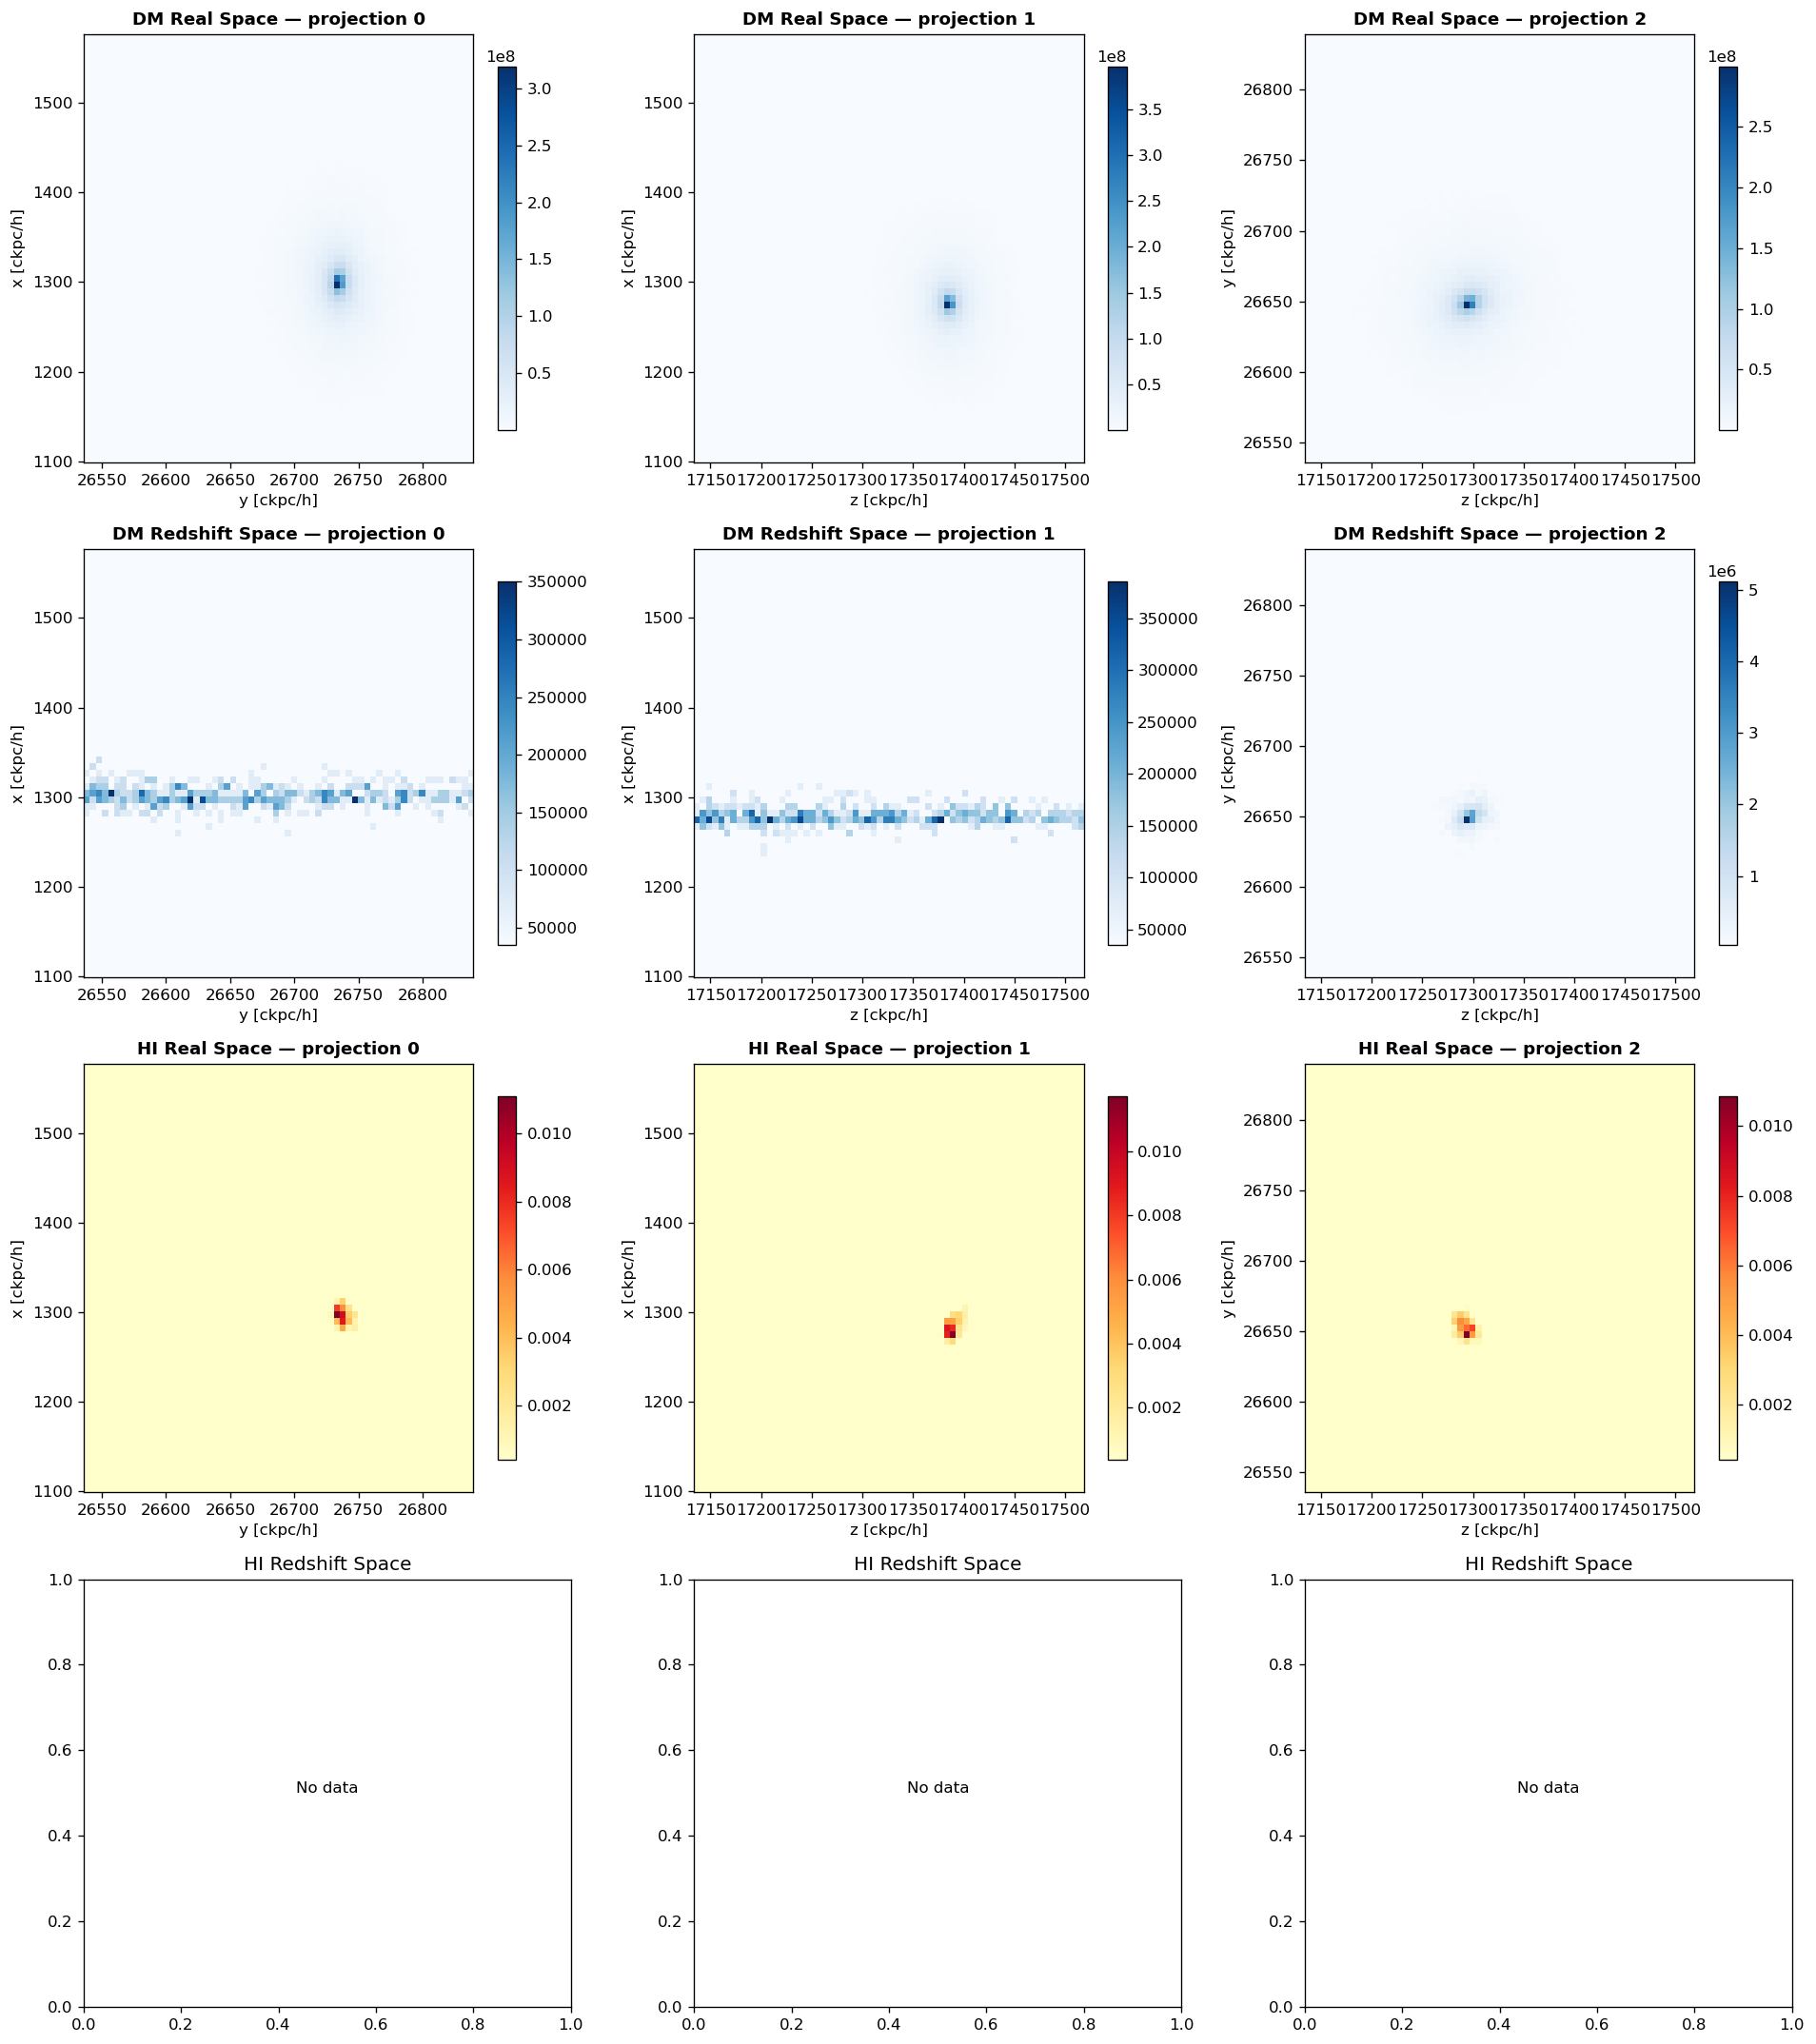

In [5]:
def plot_density_projections(dp, fields, titles, cmaps, figname):
    '''Plot x-y, x-z, y-z projections of 3D density fields with physical coordinates.'''
    nrows = len(fields)
    fig, axes = plt.subplots(nrows, 3, figsize=(16, 4.5 * nrows))
    if nrows == 1:
        axes = axes.reshape(1, -1)
    
    # Physical extents from grid edges [ckpc/h]
    x_edges = dp.grid_edges[0]
    y_edges = dp.grid_edges[1]
    z_edges = dp.grid_edges[2]
    extents = [
        [y_edges[0], y_edges[-1], x_edges[0], x_edges[-1]],  # x-y proj
        [z_edges[0], z_edges[-1], x_edges[0], x_edges[-1]],  # x-z proj
        [z_edges[0], z_edges[-1], y_edges[0], y_edges[-1]],  # y-z proj
    ]
    xlabels = ['y [ckpc/h]', 'z [ckpc/h]', 'z [ckpc/h]']
    ylabels = ['x [ckpc/h]', 'x [ckpc/h]', 'y [ckpc/h]']
    
    for row, (field, title, cmap) in enumerate(zip(fields, titles, cmaps)):
        data = getattr(dp, field)
        if data is None or np.all(data == 0):
            for ax in axes[row]:
                ax.text(0.5, 0.5, 'No data', transform=ax.transAxes, ha='center')
                ax.set_title(f'{title}')
            continue
        
        # Projections (sum along axis)
        proj_xy = np.sum(data, axis=2)
        proj_xz = np.sum(data, axis=1)
        proj_yz = np.sum(data, axis=0)
        
        for col, (proj, extent, xlabel, ylabel) in enumerate(zip(
            [proj_xy, proj_xz, proj_yz], extents, xlabels, ylabels
        )):
            ax = axes[row, col]
            vmax = np.max(proj)
            vmin = np.min(proj[proj > 0]) if np.any(proj > 0) else 0
            im = ax.imshow(proj.T, origin='lower', cmap=cmap,
                          extent=extent, vmin=vmin, vmax=vmax, aspect='auto')
            ax.set_xlabel(xlabel, fontsize=10)
            ax.set_ylabel(ylabel, fontsize=10)
            ax.set_title(f'{title} — projection {col}', fontsize=11, fontweight='bold')
            plt.colorbar(im, ax=ax, shrink=0.85)
    
    plt.tight_layout()
    fpath = os.path.join(OUTDIR, figname)
    plt.savefig(fpath, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'Saved: {fpath}')
    plt.show()

# DM real-space vs redshift-space
plot_density_projections(
    dp,
    fields=['dm_real', 'dm_rsd', 'hi_real', 'hi_rsd'],
    titles=['DM Real Space', 'DM Redshift Space', 'HI Real Space', 'HI Redshift Space'],
    cmaps=['Blues', 'Blues', 'YlOrRd', 'YlOrRd'],
    figname=f'sub{subID}_z{Z_OBS}_DM_HI_projections.png'
)

### 4.2 Visualize — UV Field & RSD Comparison

Saved: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/sub7_z0.02_UV_and_RSD.png


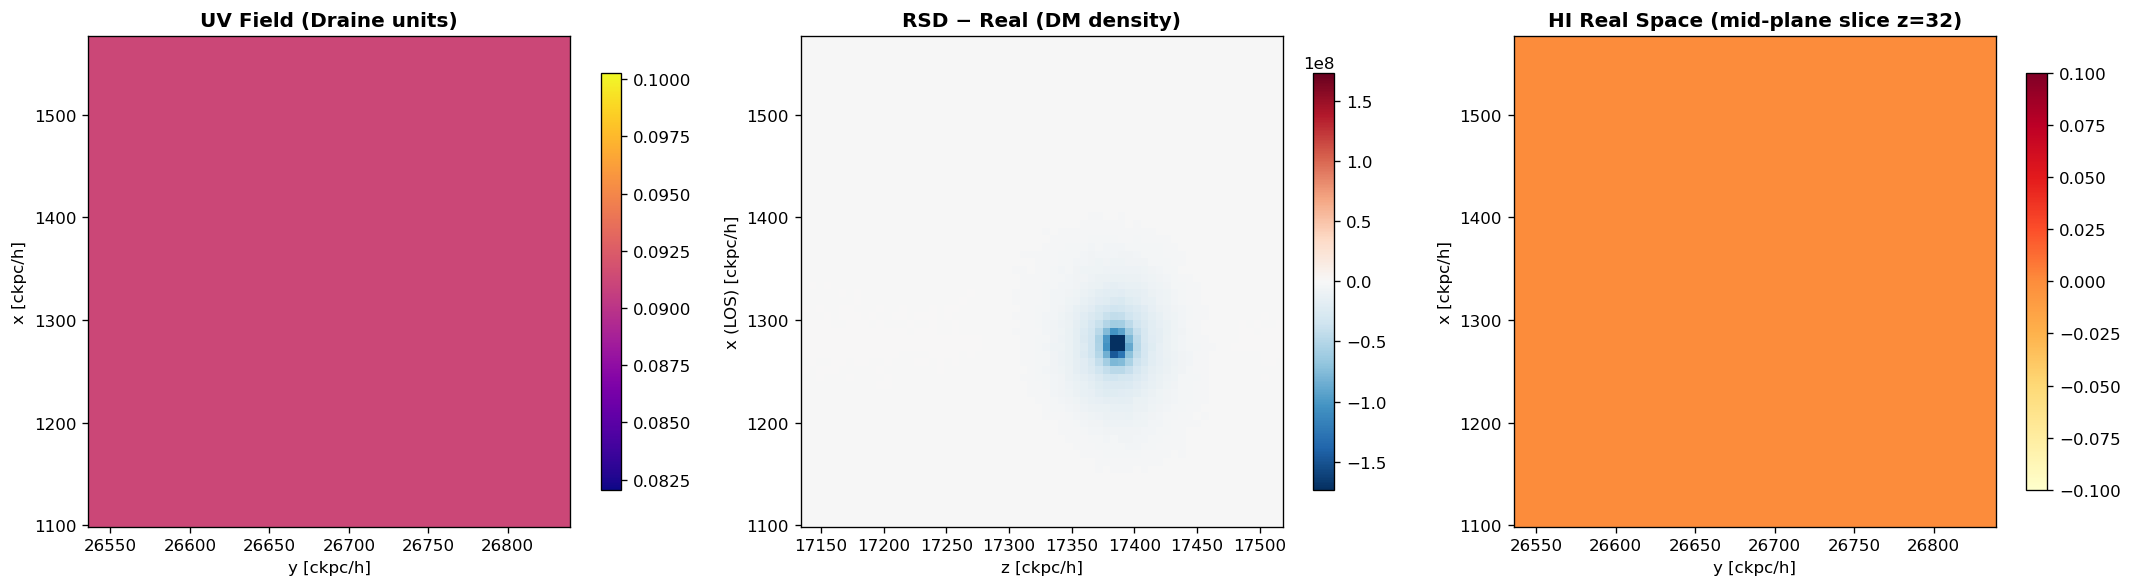

In [6]:
def plot_uv_and_rsd_shift(dp, figname):
    '''Plot UV field and RSD shift (dm_rsd - dm_real) with physical coordinates.'''
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    x_edges = dp.grid_edges[0]
    y_edges = dp.grid_edges[1]
    z_edges = dp.grid_edges[2]
    
    # UV field (x-y projection)
    if dp.uv_field is not None and np.any(dp.uv_field > 0):
        uv_xy = np.sum(dp.uv_field, axis=2)
        vmax = np.max(uv_xy)
        vmin = np.min(uv_xy[uv_xy > 0]) if np.any(uv_xy > 0) else 0
        im = axes[0].imshow(uv_xy.T, origin='lower', cmap='plasma',
                           extent=[y_edges[0], y_edges[-1], x_edges[0], x_edges[-1]],
                           vmin=vmin, vmax=vmax, aspect='auto')
        axes[0].set_title('UV Field (Draine units)', fontweight='bold')
        axes[0].set_xlabel('y [ckpc/h]'); axes[0].set_ylabel('x [ckpc/h]')
        plt.colorbar(im, ax=axes[0], shrink=0.85)
    else:
        axes[0].text(0.5, 0.5, 'No UV data', transform=axes[0].transAxes, ha='center')
    
    # RSD shift = dm_rsd - dm_real (along LOS = x-axis)
    if dp.dm_real is not None and dp.dm_rsd is not None:
        rsd_diff = dp.dm_rsd - dp.dm_real
        if np.any(rsd_diff != 0):
            vmax = max(abs(rsd_diff.min()), abs(rsd_diff.max()))
            diff_xz = np.sum(rsd_diff, axis=1)
            im = axes[1].imshow(diff_xz.T, origin='lower', cmap='RdBu_r',
                               extent=[z_edges[0], z_edges[-1], x_edges[0], x_edges[-1]],
                               vmin=-vmax, vmax=vmax, aspect='auto')
            axes[1].set_title('RSD − Real (DM density)', fontweight='bold')
            axes[1].set_xlabel('z [ckpc/h]'); axes[1].set_ylabel('x (LOS) [ckpc/h]')
            plt.colorbar(im, ax=axes[1], shrink=0.85)
        else:
            axes[1].text(0.5, 0.5, 'RSD = Real (no shift)', transform=axes[1].transAxes, ha='center')
    
    # HI density slice at mid-plane (x-y slice)
    if dp.hi_real is not None and np.any(dp.hi_real > 0):
        mid = dp.hi_real.shape[2] // 2
        hi_slice = dp.hi_real[:, :, mid]
        vmax = np.max(hi_slice)
        vmin = np.min(hi_slice[hi_slice > 0]) if np.any(hi_slice > 0) else 0
        im = axes[2].imshow(hi_slice.T, origin='lower', cmap='YlOrRd',
                           extent=[y_edges[0], y_edges[-1], x_edges[0], x_edges[-1]],
                           vmin=vmin, vmax=vmax, aspect='auto')
        axes[2].set_title(f'HI Real Space (mid-plane slice z={mid})', fontweight='bold')
        axes[2].set_xlabel('y [ckpc/h]'); axes[2].set_ylabel('x [ckpc/h]')
        plt.colorbar(im, ax=axes[2], shrink=0.85)
    else:
        axes[2].text(0.5, 0.5, 'No HI data', transform=axes[2].transAxes, ha='center')
    
    plt.tight_layout()
    fpath = os.path.join(OUTDIR, figname)
    plt.savefig(fpath, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'Saved: {fpath}')
    plt.show()

plot_uv_and_rsd_shift(dp, f'sub{subID}_z{Z_OBS}_UV_and_RSD.png')

---
## 5. Task 2 — Mock Radio Cubes

Generate synthetic HI data cubes with:
- **Noise:** 0.5 mJy/beam Gaussian RMS
- **Beam A:** 10 arcsec FWHM (high resolution)
- **Beam B:** 3 arcmin FWHM (low resolution, single-dish like)


### 5.1 High Resolution — 10 arcsec Beam

In [7]:
# ===== Cube A: 10 arcsec beam =====
BEAM_A_BMAJ = 10 * U.arcsec
NOISE_RMS  = 0.5e-3 * U.Jy / U.beam   # 0.5 mJy/beam

print(f'Beam A: {BEAM_A_BMAJ.to(U.arcsec):.0f} FWHM, noise RMS = {NOISE_RMS.to(U.mJy/U.beam):.1f}')

# Adaptive FOV: 1.1× particle extent per axis, floor at 3× beam FWHM
sky_fov_y = max(y_extent_arcsec, 3 * BEAM_A_BMAJ.value)
sky_fov_z = max(z_extent_arcsec, 3 * BEAM_A_BMAJ.value)
px_size_a = BEAM_A_BMAJ.value / 3.0  # ~3 pixels per beam FWHM
n_px_x = int(np.ceil(sky_fov_y / px_size_a))
n_px_y = int(np.ceil(sky_fov_z / px_size_a))
if n_px_x % 2 == 1:
    n_px_x += 1
if n_px_y % 2 == 1:
    n_px_y += 1

# Adaptive spectral axis
channel_width_a = max(v_extent_kms / 32, 5.0)  # at least 32 channels, min 5 km/s
n_channels_a = int(np.ceil(v_extent_kms / channel_width_a))
if n_channels_a % 2 == 1:
    n_channels_a += 1

print(f'  FOV: {n_px_x*px_size_a:.0f}\" × {n_px_y*px_size_a:.0f}\" ({n_px_x}×{n_px_y} pix, {px_size_a:.1f}\"/pix)')
print(f'  Spectral: {n_channels_a} ch × {channel_width_a:.1f} km/s = {n_channels_a*channel_width_a:.0f} km/s')

datacube_a = DataCube(
    n_px_x=n_px_x, n_px_y=n_px_y, n_channels=n_channels_a,
    px_size=px_size_a * U.arcsec,
    channel_width=channel_width_a * U.km / U.s,
    spectral_centre=source.vsys,
    ra=source.ra, dec=source.dec,
    spectral_unit='MHz',
)

beam_a = GaussianBeam(bmaj=BEAM_A_BMAJ, bmin=BEAM_A_BMAJ, bpa=0 * U.deg, truncate=4.0)
noise_a = GaussianNoise(rms=NOISE_RMS, seed=42)
spectral_model = GaussianSpectrum(sigma='thermal')
sph_kernel = CubicSplineKernel()

M_a = Martini(source=source, datacube=datacube_a,
              beam=beam_a, noise=noise_a,
              spectral_model=spectral_model, sph_kernel=sph_kernel)

print('Inserting source...')
M_a.insert_source_in_cube(progressbar=False)
print('Adding noise...')
M_a.add_noise()
print('Convolving beam...')
M_a.convolve_beam()

fits_a = os.path.join(OUTDIR, f'sub{subID}_z{Z_OBS}_10arcsec.fits')
M_a.write_fits(fits_a)
print(f'Saved: {fits_a}')

Beam A: 10 arcsec FWHM, noise RMS = 0.5 mJy / beam
  FOV: 100" × 133" (30×40 pix, 3.3"/pix)
  Spectral: 32 ch × 11.4 km/s = 364 km/s
Source module contained 120 particles with total HI mass of 1.60e+01 solMass.
Pruned particles that will not contribute to data cube, 120 particles remaining with total HI mass of 1.60e+01 solMass.
Inserting source...
Initializing spectra...
Spectra initialized.
Source inserted.
  Flux density in cube: 2.67e-14 Jy
  Mass in cube (assuming distance 89.86 Mpc and a spatially resolved source): 1.53e+01 solMass
    [96% of initial source mass]
  Maximum pixel: 5.79e-18 Jy / arcsec2
  Median non-zero pixel: 1.74e-19 Jy / arcsec2
Adding noise...
Noise added.
  Noise cube RMS: 2.20e-05 Jy / arcsec2 (before beam convolution).
  Data cube RMS after noise addition (before beam convolution): 2.20e-05 Jy / arcsec2
Convolving beam...
Beam convolved.
  Data cube RMS after beam convolution: 5.39e-04 Jy / beam
  Maximum pixel: 1.94e-03 Jy / beam
  Median non-zero pixel: 

### 5.2 Low Resolution — 3 arcmin Beam

In [8]:
# ===== Cube B: 3 arcmin beam =====
BEAM_B_BMAJ = 3 * U.arcmin

print(f'\nBeam B: {BEAM_B_BMAJ.to(U.arcmin):.0f} FWHM, noise RMS = {NOISE_RMS.to(U.mJy/U.beam):.1f}')

# Adaptive FOV: 1.1× particle extent per axis, floor at 3× beam FWHM
sky_fov_b_y = max(y_extent_arcsec, 3 * BEAM_B_BMAJ.to_value(U.arcsec))
sky_fov_b_z = max(z_extent_arcsec, 3 * BEAM_B_BMAJ.to_value(U.arcsec))
px_size_b = BEAM_B_BMAJ.to_value(U.arcsec) / 3.0  # ~3 pixels per beam FWHM
n_px_x_b = int(np.ceil(sky_fov_b_y / px_size_b))
n_px_y_b = int(np.ceil(sky_fov_b_z / px_size_b))
if n_px_x_b % 2 == 1:
    n_px_x_b += 1
if n_px_y_b % 2 == 1:
    n_px_y_b += 1

# Reuse same spectral binning as Cube A
channel_width_b = channel_width_a
n_channels_b = n_channels_a

print(f'  FOV: {n_px_x_b*px_size_b:.0f}\" × {n_px_y_b*px_size_b:.0f}\" ({n_px_x_b}×{n_px_y_b} pix, {px_size_b:.0f}\"/pix)')
print(f'  Spectral: {n_channels_b} ch × {channel_width_b:.1f} km/s = {n_channels_b*channel_width_b:.0f} km/s')

datacube_b = DataCube(
    n_px_x=n_px_x_b, n_px_y=n_px_y_b, n_channels=n_channels_b,
    px_size=px_size_b * U.arcsec,
    channel_width=channel_width_b * U.km / U.s,
    spectral_centre=source.vsys,
    ra=source.ra, dec=source.dec,
    spectral_unit='MHz',
)

beam_b = GaussianBeam(bmaj=BEAM_B_BMAJ, bmin=BEAM_B_BMAJ, bpa=0 * U.deg, truncate=4.0)
noise_b = GaussianNoise(rms=NOISE_RMS, seed=42)

M_b = Martini(source=source, datacube=datacube_b,
              beam=beam_b, noise=noise_b,
              spectral_model=GaussianSpectrum(sigma='thermal'), sph_kernel=CubicSplineKernel())

print('Inserting source...')
M_b.insert_source_in_cube(progressbar=False)
print('Adding noise...')
M_b.add_noise()
print('Convolving beam...')
M_b.convolve_beam()

fits_b = os.path.join(OUTDIR, f'sub{subID}_z{Z_OBS}_3arcmin.fits')
M_b.write_fits(fits_b)
print(f'Saved: {fits_b}')


Beam B: 3 arcmin FWHM, noise RMS = 0.5 mJy / beam
  FOV: 600" × 600" (10×10 pix, 60"/pix)
  Spectral: 32 ch × 11.4 km/s = 364 km/s
Source module contained 120 particles with total HI mass of 1.60e+01 solMass.
Pruned particles that will not contribute to data cube, 120 particles remaining with total HI mass of 1.60e+01 solMass.
Inserting source...
Initializing spectra...
Spectra initialized.
Source inserted.
  Flux density in cube: 2.80e-14 Jy
  Mass in cube (assuming distance 89.86 Mpc and a spatially resolved source): 1.60e+01 solMass
    [100% of initial source mass]
  Maximum pixel: 1.81e-18 Jy / arcsec2
  Median non-zero pixel: 6.58e-19 Jy / arcsec2
Adding noise...
Noise added.
  Noise cube RMS: 6.78e-08 Jy / arcsec2 (before beam convolution).
  Data cube RMS after noise addition (before beam convolution): 6.78e-08 Jy / arcsec2
Convolving beam...
Beam convolved.
  Data cube RMS after beam convolution: 5.54e-04 Jy / beam
  Maximum pixel: 1.70e-03 Jy / beam
  Median non-zero pixel: 

## 6. Visualize the Data Cubes

### 6.1 Cube A — 10 arcsec Resolution

Saved: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/sub7_z0.02_10arcsec_viz.png


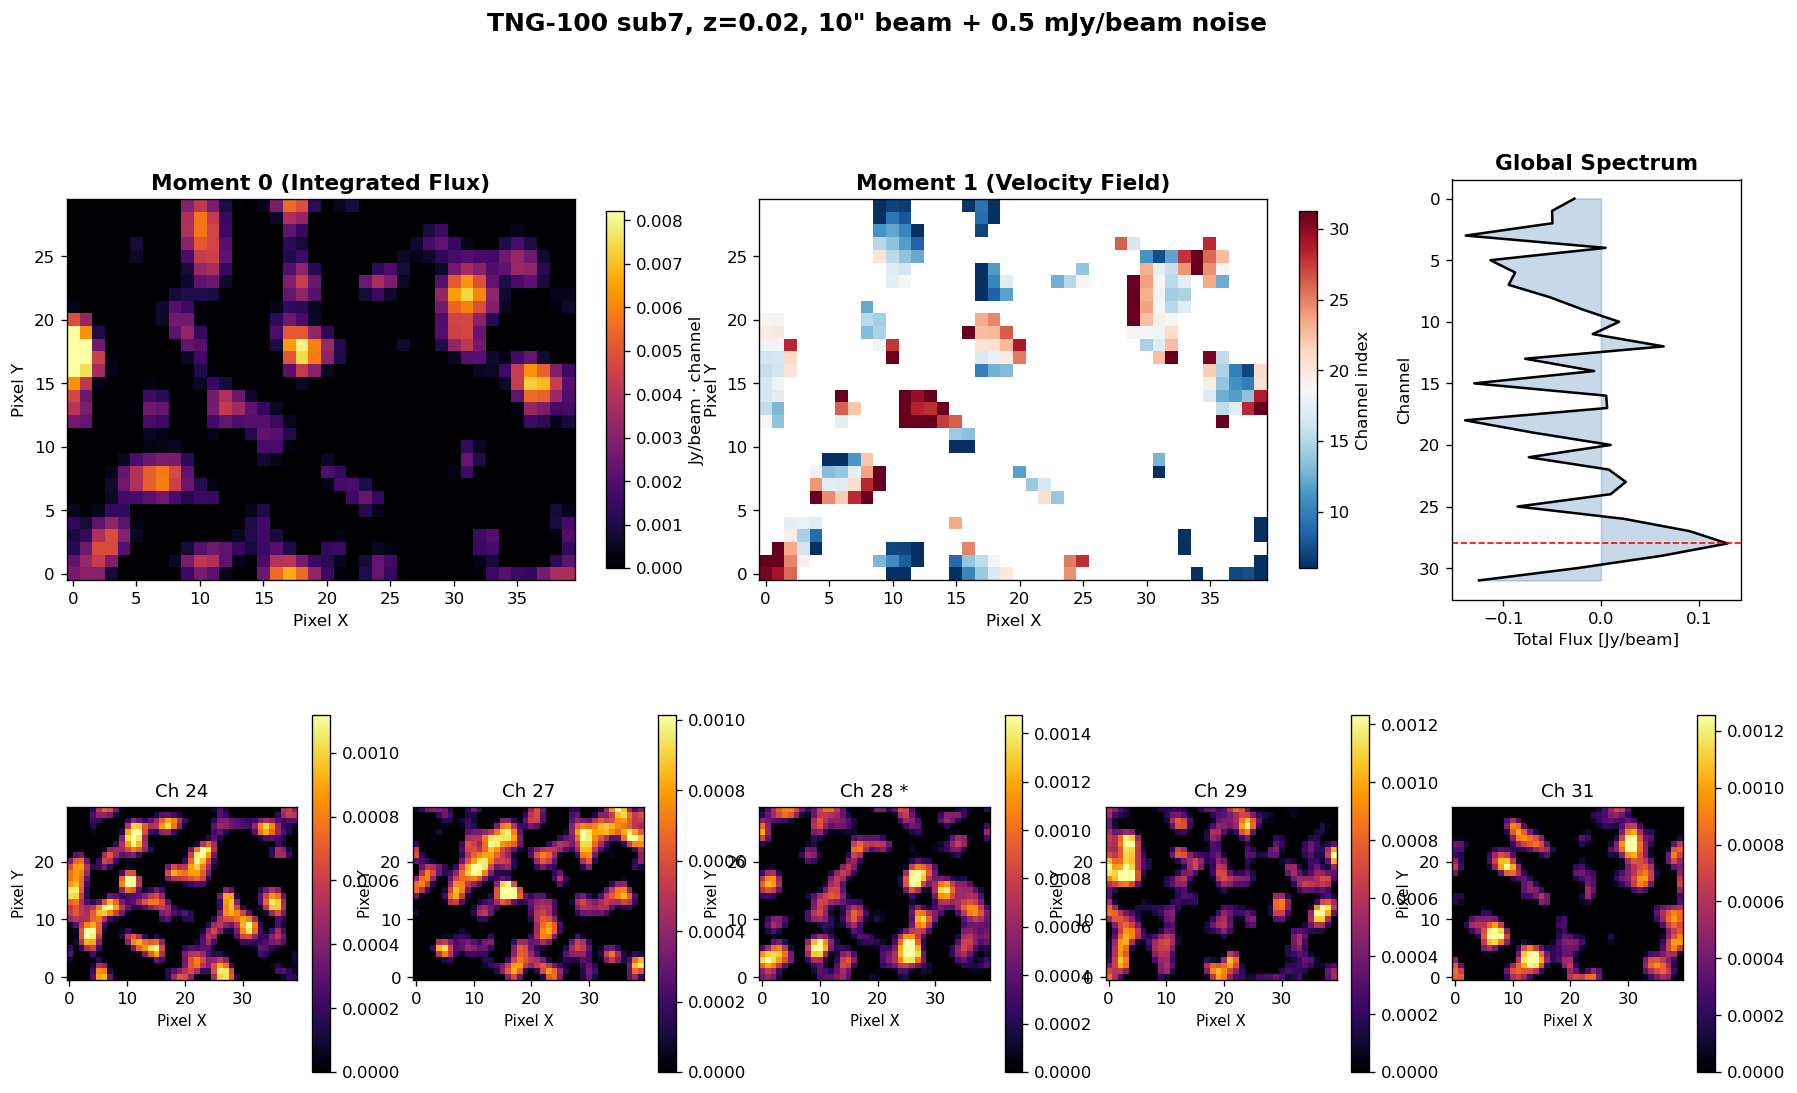

In [9]:
from astropy.io import fits
from astropy.wcs import WCS

def compute_moments(cube_data):
    mom0 = np.sum(cube_data, axis=0)
    nchan = cube_data.shape[0]
    with np.errstate(invalid='ignore', divide='ignore'):
        mom1 = np.sum(cube_data * np.arange(nchan)[:, np.newaxis, np.newaxis], axis=0) / np.maximum(mom0, 1e-30)
    mom1[~np.isfinite(mom1)] = np.nan
    return mom0, mom1

def visualize_cube(fits_path, title_prefix, save_name):
    with fits.open(fits_path) as hdul:
        data = hdul[0].data
        header = hdul[0].header

    mom0, mom1 = compute_moments(data)
    rms = np.std(data[0])
    signal_mask = mom0 > 3 * rms

    nchan = data.shape[0]
    peak_chan = np.argmax(np.sum(data, axis=(1, 2)))
    chans = sorted(set([max(0, peak_chan - 4), max(0, peak_chan - 1),
                        peak_chan,
                        min(nchan - 1, peak_chan + 1), min(nchan - 1, peak_chan + 4)]))

    fig = plt.figure(figsize=(18, 10))

    # Moment 0
    ax0 = fig.add_subplot(2, 5, (1, 2))
    vmax = np.percentile(mom0[signal_mask], 98) if signal_mask.any() and mom0[signal_mask].size > 0 else mom0.max()
    im0 = ax0.imshow(mom0.T, origin='lower', cmap='inferno', vmin=0, vmax=vmax)
    ax0.set_xlabel('Pixel X'); ax0.set_ylabel('Pixel Y')
    ax0.set_title('Moment 0 (Integrated Flux)', fontsize=13, fontweight='bold')
    plt.colorbar(im0, ax=ax0, label='Jy/beam \u00b7 channel', shrink=0.85)

    # Moment 1
    ax1 = fig.add_subplot(2, 5, (3, 4))
    mom1_m = np.where(signal_mask, mom1, np.nan)
    im1 = ax1.imshow(mom1_m.T, origin='lower', cmap='RdBu_r',
                     vmin=np.nanpercentile(mom1_m, 10) if np.any(np.isfinite(mom1_m)) else 0,
                     vmax=np.nanpercentile(mom1_m, 90) if np.any(np.isfinite(mom1_m)) else 1)
    ax1.set_xlabel('Pixel X'); ax1.set_ylabel('Pixel Y')
    ax1.set_title('Moment 1 (Velocity Field)', fontsize=13, fontweight='bold')
    plt.colorbar(im1, ax=ax1, label='Channel index', shrink=0.85)

    # Spectrum
    ax_s = fig.add_subplot(2, 5, 5)
    spec = np.sum(data, axis=(1, 2))
    ax_s.plot(spec, np.arange(nchan), 'k-', lw=1.5)
    ax_s.fill_betweenx(np.arange(nchan), 0, spec, alpha=0.3, color='steelblue')
    ax_s.set_xlabel('Total Flux [Jy/beam]'); ax_s.set_ylabel('Channel')
    ax_s.set_title('Global Spectrum', fontsize=13, fontweight='bold')
    ax_s.axhline(peak_chan, color='red', ls='--', lw=1)
    ax_s.invert_yaxis()

    # Channel maps
    for j, ch in enumerate(chans):
        ax = fig.add_subplot(2, 5, 6 + j)
        ch_data = data[ch]
        vmax_ch = np.percentile(ch_data, 99) if ch_data.size > 0 else 1e-30
        im = ax.imshow(ch_data.T, origin='lower', cmap='inferno', vmin=0, vmax=vmax_ch)
        ax.set_xlabel('Pixel X', fontsize=9); ax.set_ylabel('Pixel Y', fontsize=9)
        label = f'Ch {ch}' + (' *' if ch == peak_chan else '')
        ax.set_title(label, fontsize=11)
        plt.colorbar(im, ax=ax, shrink=0.85)

    plt.suptitle(title_prefix, fontsize=15, fontweight='bold', y=1.02)
    fpath = os.path.join(OUTDIR, save_name)
    plt.savefig(fpath, dpi=150, bbox_inches='tight', facecolor='white')
    print(f'Saved: {fpath}')
    plt.show()

# Visualize 10 arcsec cube
visualize_cube(fits_a, f'TNG-100 sub{subID}, z={Z_OBS}, 10\" beam + 0.5 mJy/beam noise',
               f'sub{subID}_z{Z_OBS}_10arcsec_viz.png')

### 6.2 Cube B — 3 arcmin Resolution

Saved: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/sub7_z0.02_3arcmin_viz.png


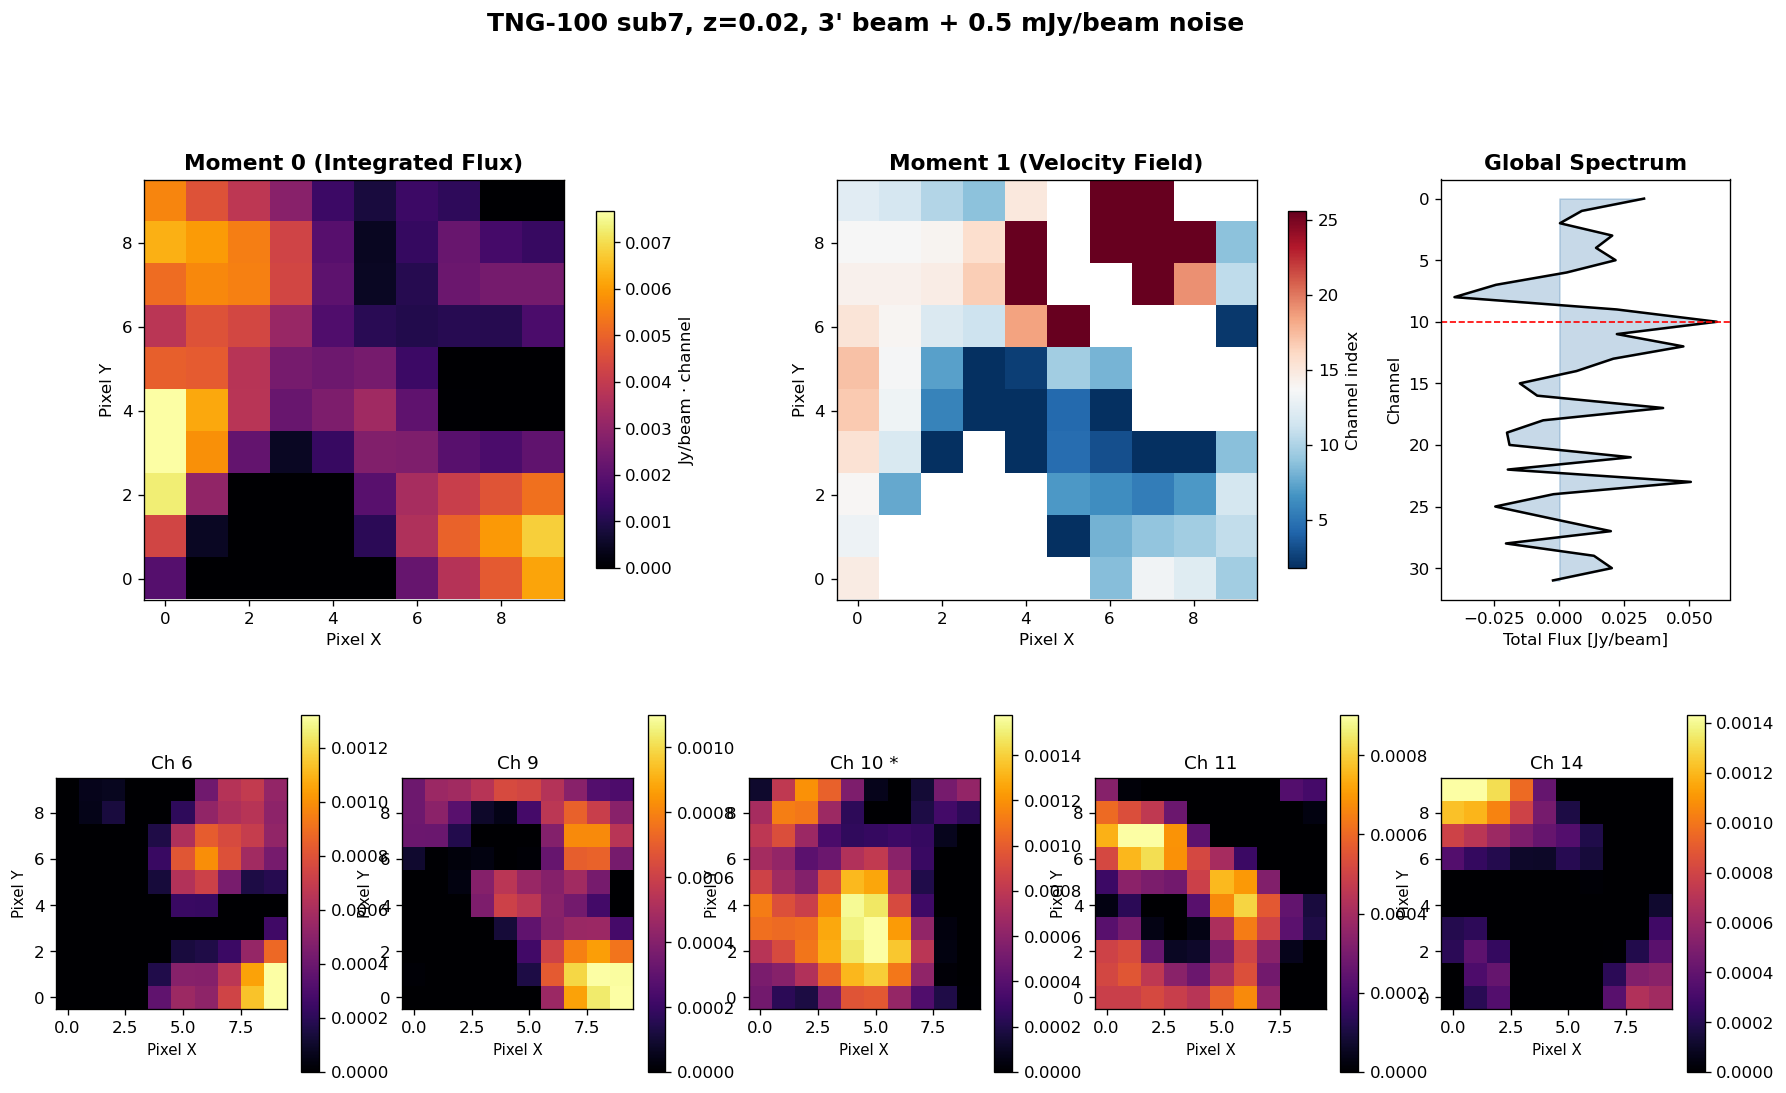

In [10]:
# Visualize 3 arcmin cube
visualize_cube(fits_b, f'TNG-100 sub{subID}, z={Z_OBS}, 3\' beam + 0.5 mJy/beam noise',
               f'sub{subID}_z{Z_OBS}_3arcmin_viz.png')

### 6.3 Side-by-Side Comparison

Saved: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/sub7_z0.02_comparison.png


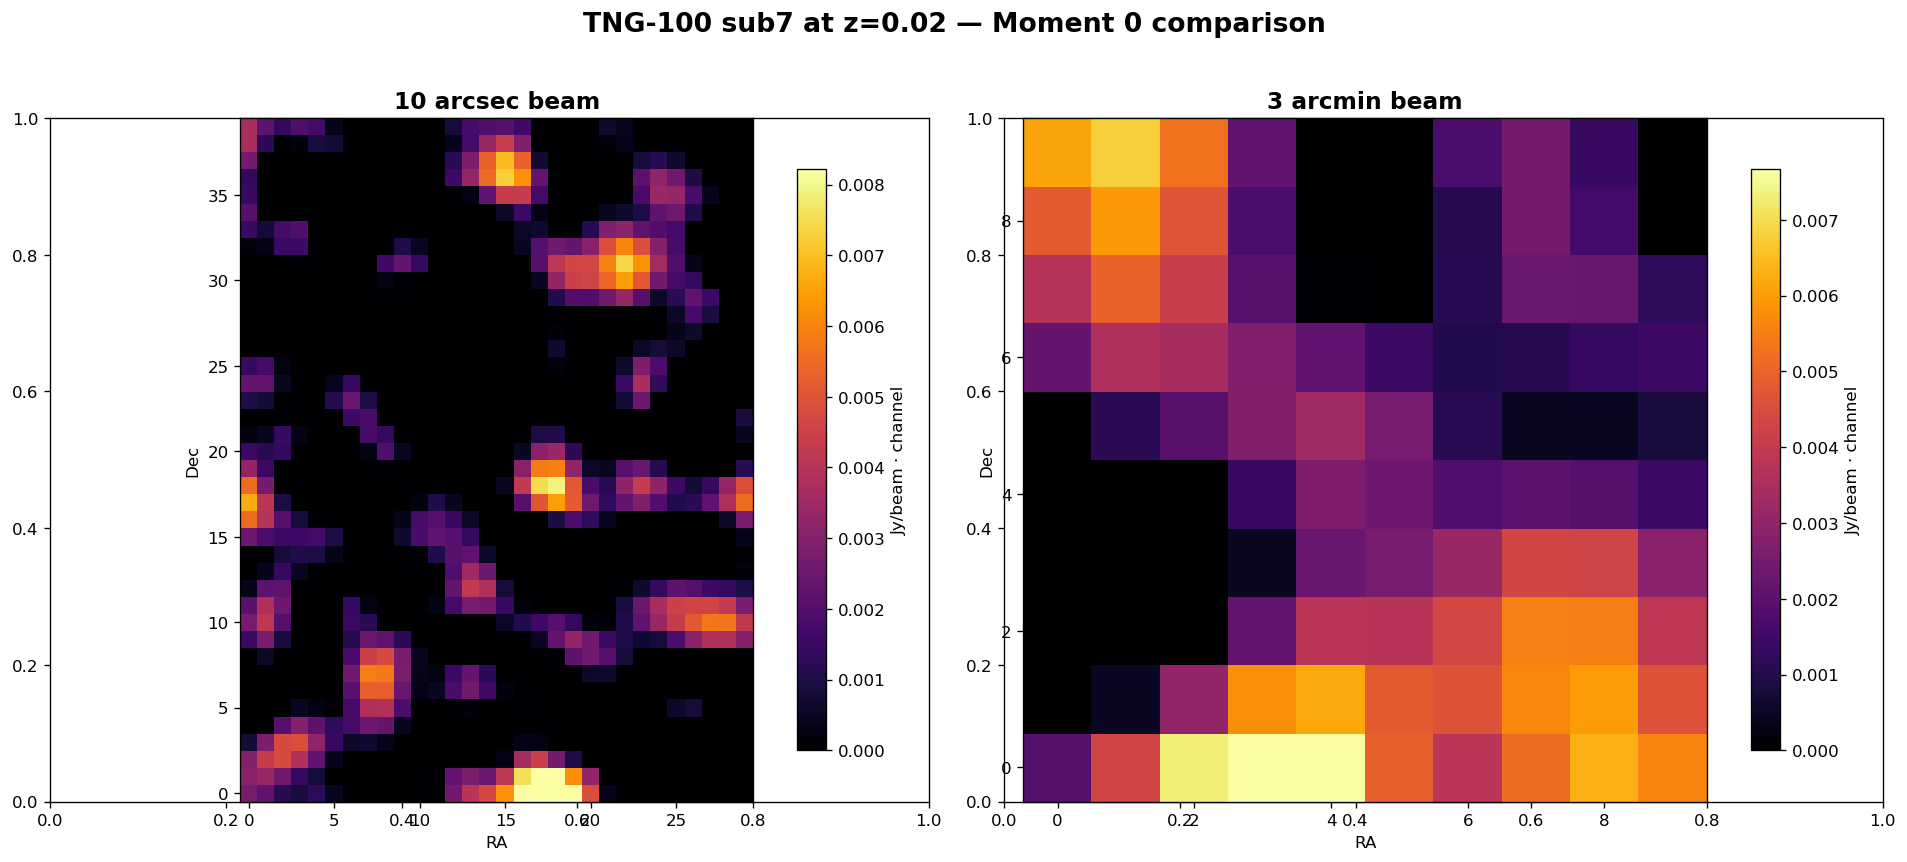

In [11]:
# Side-by-side moment 0 comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for idx, (fpath, label) in enumerate(zip([fits_a, fits_b], ['10 arcsec beam', '3 arcmin beam'])):
    with fits.open(fpath) as hdul:
        data = hdul[0].data
        header = hdul[0].header
        
    mom0 = np.sum(data, axis=0)
    rms = np.std(data[0])
    signal = mom0 > 3 * rms
    vmax = np.percentile(mom0[signal], 98) if signal.any() and mom0[signal].size > 0 else mom0.max()

    ax = fig.add_subplot(1, 2, idx + 1)
    im = ax.imshow(mom0, origin='lower', cmap='inferno', vmin=0, vmax=vmax)
    ax.set_xlabel('RA'); ax.set_ylabel('Dec')
    ax.set_title(f'{label}', fontsize=14, fontweight='bold')
    plt.colorbar(im, ax=ax, label='Jy/beam \u00b7 channel', shrink=0.85)

plt.suptitle(f'TNG-100 sub{subID} at z={Z_OBS} \u2014 Moment 0 comparison', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
fpath = os.path.join(OUTDIR, f'sub{subID}_z{Z_OBS}_comparison.png')
plt.savefig(fpath, dpi=150, bbox_inches='tight', facecolor='white')
print(f'Saved: {fpath}')
plt.show()

## 7. Summary

### Generated Files

All data products saved to `examplefiles/`:

| File | Description |
|------|-------------|
| `sub7_z0.02_data_products.hdf5` | 3D grids: UV field, DM/HI/H₂ (real + RSD) |
| `sub7_z0.02_10arcsec.fits` | Data cube — 10 arcsec beam, 0.5 mJy/beam noise |
| `sub7_z0.02_3arcmin.fits` | Data cube — 3 arcmin beam, 0.5 mJy/beam noise |

### Generated Figures

| Figure | Content |
|--------|---------|
| `*_DM_HI_projections.png` | 4-row panel: DM real, DM RSD, HI real, HI RSD projections |
| `*_UV_and_RSD.png` | UV field, RSD−Real difference, HI mid-plane slice |
| `*_10arcsec_viz.png` | Cube A: moment maps, spectrum, 5 channel maps |
| `*_3arcmin_viz.png` | Cube B: moment maps, spectrum, 5 channel maps |
| `*_comparison.png` | Side-by-side Moment 0 comparison |


In [12]:
print('='*60)
print('  astrovodka Demo — Complete')
print('='*60)
print(f'  Subhalo: {subID}, observed z = {Z_OBS}')
print(f'  D_L = {DL:.1f}, D_A = {DA:.1f}')
print(f'  Total HI mass: {source.input_mass:.2e}')
print(f'  Total H2 mass: {source.m_H2_g.sum():.2e}')
print()
print(f'  Data products: {h5_path}')
print(f'  Cube A (10\"):  {os.path.basename(fits_a)}')
print(f'  Cube B (3\'):   {os.path.basename(fits_b)}')
print()
print(f'  All files in: {OUTDIR}')
print('Done!')


  astrovodka Demo — Complete
  Subhalo: 7, observed z = 0.02
  D_L = 89.9 Mpc, D_A = 86.4 Mpc
  Total HI mass: 1.60e+01 solMass
  Total H2 mass: 0.00e+00 solMass

  Data products: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/sub7_z0.02_data_products.hdf5
  Cube A (10"):  sub7_z0.02_10arcsec.fits
  Cube B (3'):   sub7_z0.02_3arcmin.fits

  All files in: /home/zerui603/work/astrovodka/astrovodka.0.1/examples/examplefiles/
Done!
